# Leaky mode field for Hollow Core waveguide

We have seen in 1.3 that determining the radiation field for the hollow core guide is a delicate process, requiring resolution of numerous spikes in the radiation transform.  The resulting field function is slow to evaluate due to many integration points.  In contrast, the calculation of the leaky mode field, which is detailed in this tutorial, is quick both to build and to evaluate, and has the additional benefit of not requiring extra computational load to determine values at large distances along the direction of propagation.

After building the leaky field for a given input signal, we examine how well that field approximates the true induced field in the guide. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from slab2 import Slab, Propagator, real_contour

plt.style.use('dark_background')
%matplotlib widget

# Setup Waveguide and input fields

In [64]:
A = Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[180, 40, 200, 40, 180], wl=5.83e-06)

In [242]:
half_width = 1
shift = .5
amplitude = 1

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

f0 = quadratic_piecewise

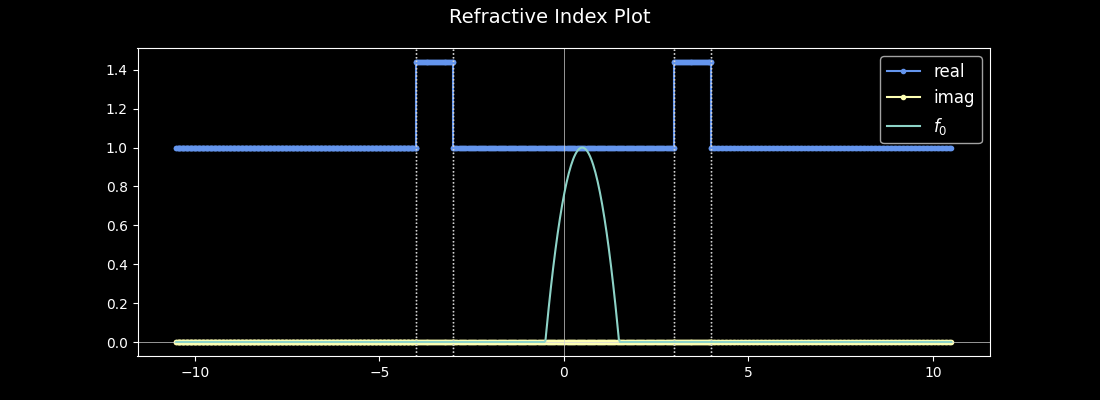

In [66]:
A.plot_refractive_index(ms=3, marker='o');
A.add_1d_plot(f0, label='$f_0$')

## Guided Modes

As in notebook 1.3, we avoid the need for calculating the guided mode profiles of the hollow core guide by restricting our interest to an input field localized in the low index core region.

## Radiation Field

We compute this all at once.

In [67]:
P = Propagator(A, f0=f0, window=[Lx, Rx], calculate_guided_field=False)

In [68]:
P.add_contour(real_contour(.001, A.Z_evanescent, 1000))

P.add_contour(real_contour(.515, .525, 120))
P.add_contour(real_contour(1.02, 1.06, 50))
P.add_contour(real_contour(1.53, 1.58, 50))
P.add_contour(real_contour(2.05, 2.1, 50))

P.add_contour(real_contour(A.Z_evanescent, 30, 200))

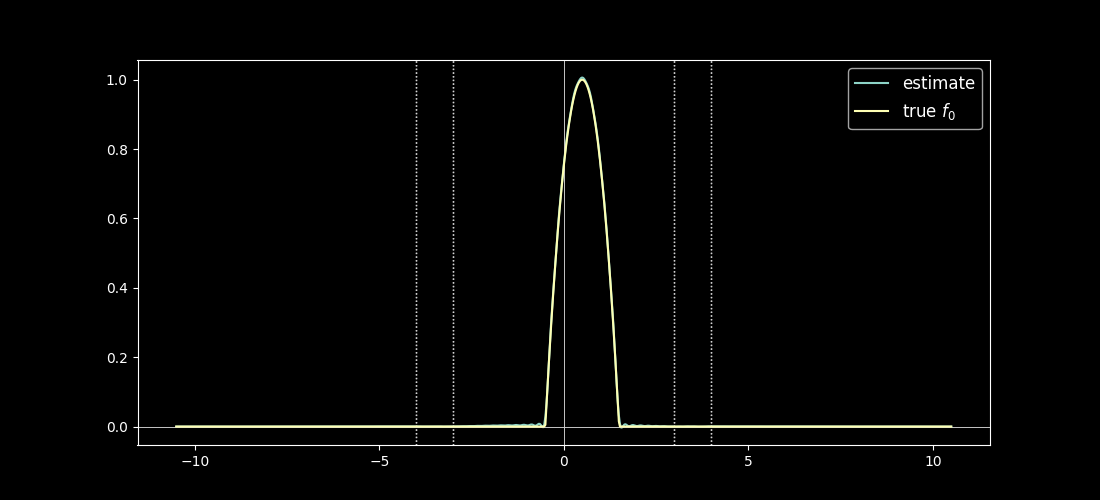

In [69]:
A.plot_field_1d(P, label='estimate') 
A.add_1d_plot(f0, label='true $f_0$')


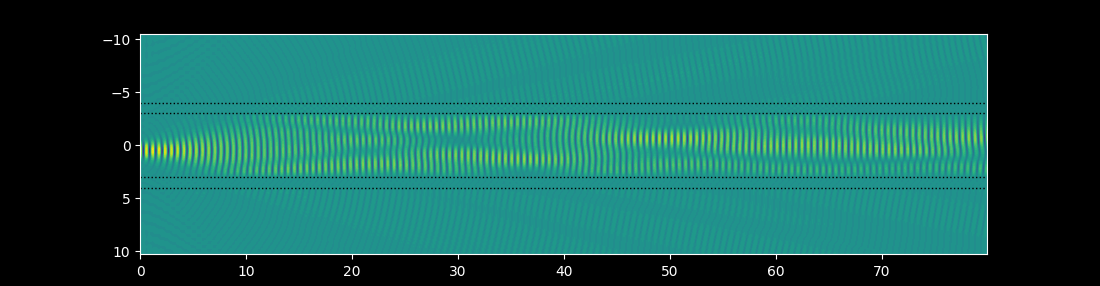

In [71]:
zmin, zmax=0, 80
A.plot_field_2d(P, zmin=zmin, zmax=zmax, zref=int((zmax-zmin)*15),
                colorbar_nticks=5, maxdim=11, layout='horizontal',
                colorbar=False,
               );

# Leaky Field

We now calculate the leaky field.  This is greatly streamlined by the built in leaky modefinding routines.
First we look for their propagation constants:

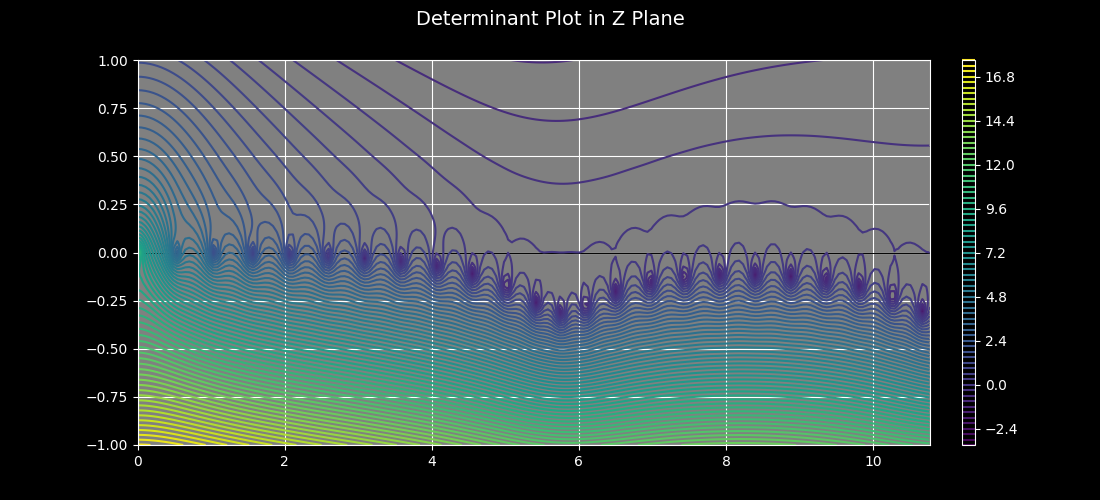

In [72]:
A.eigenvalue_plot(0, A.Z_evanescent, -1, 1);

We now find their locations in that window:

In [203]:
A.get_leaky_propagation_constants(0, A.Z_evanescent, -1, 1);
A.plot_points(A.leaky_prop_constants);

Now we get the leaky modes and form the leaky mode field associated with the input:

In [204]:
A.get_leaky_modes(rounding=10);
Leaky = P.get_leaky_field()

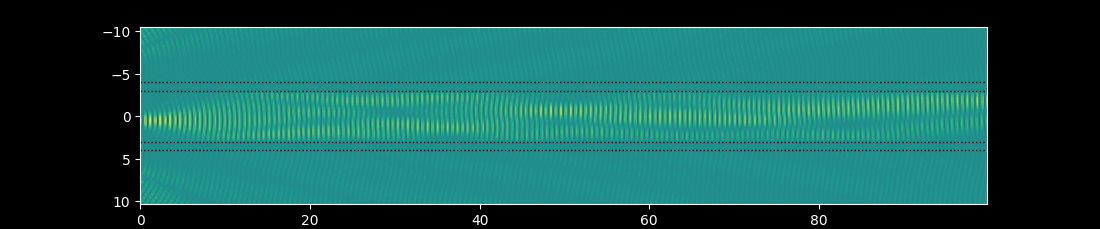

In [205]:
A.plot_field_2d(Leaky, zmin=zmin, zmax=zmax, zref=int((zmax-zmin)*6),
                colorbar_nticks=5, maxdim=11, layout='horizontal',
                colorbar=False,
               );

This appears quite similar to the true field seen in the previous section.  Let's compare more directly:

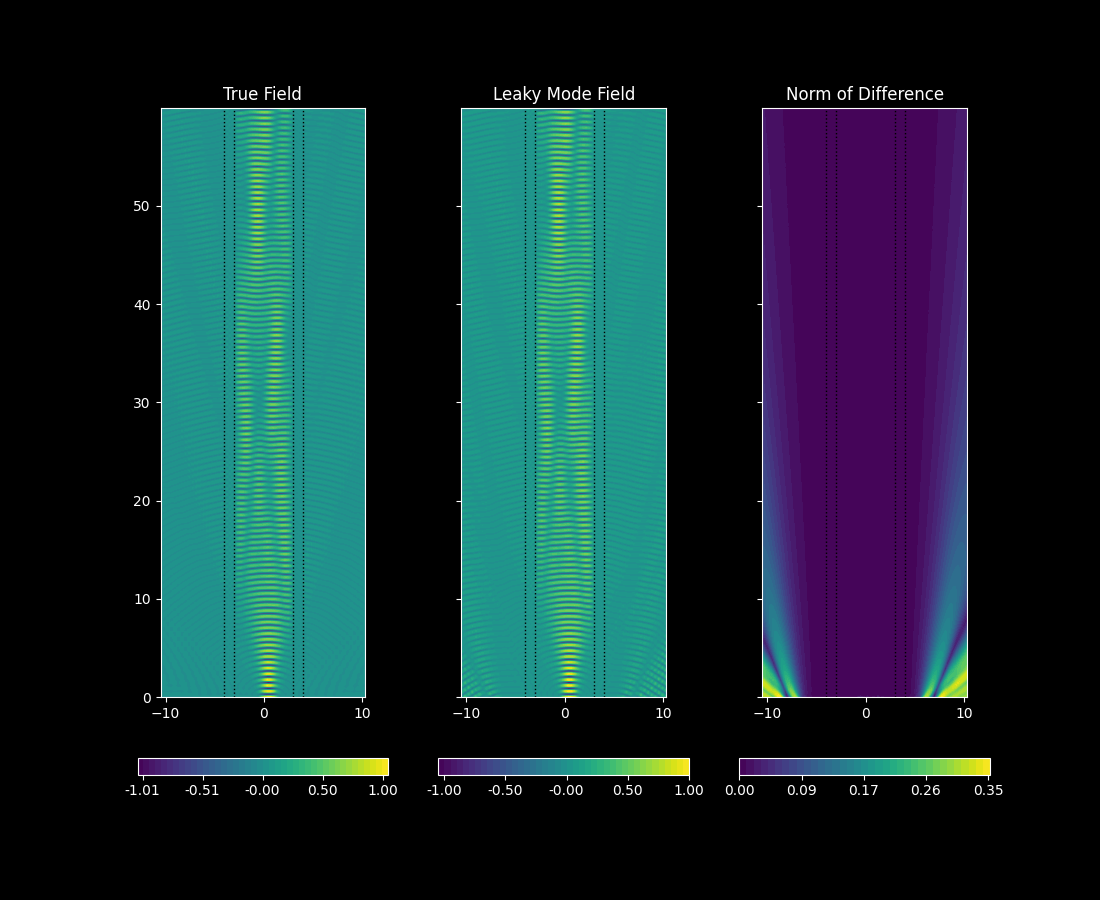

In [76]:
plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize=(11,9))
zmin = 0
zmax = 60
zref = int((zmax-zmin)*20)
zs = np.linspace(zmin, zmax, zref)

A.add_2d_plot(P.Radiation, ax=ax1, zs=zs);
ax1.set_title('True Field');

A.add_2d_plot(Leaky, ax=ax2,  zs=zs);
ax2.set_title('Leaky Mode Field');

A.add_2d_plot(np.abs(P.Radiation - Leaky), ax=ax3, zs=zs, xstride=5);
ax3.set_title('Norm of Difference');

The leaky field clearly approximates the true field well as we move in the direction of propagation.  This holds regardless of the transverse coordinate, although the approximation takes longer to occur farther from the core region.  

## Using fewer leaky modes

For the leaky field above, we used all leaky modes with real part less than the value where the radiation modes of the associated guide become evanescent.  Here we investigate what occurs if we use fewer modes.  We repeat the process for sequentially larger numbers of modes.

### Two modes

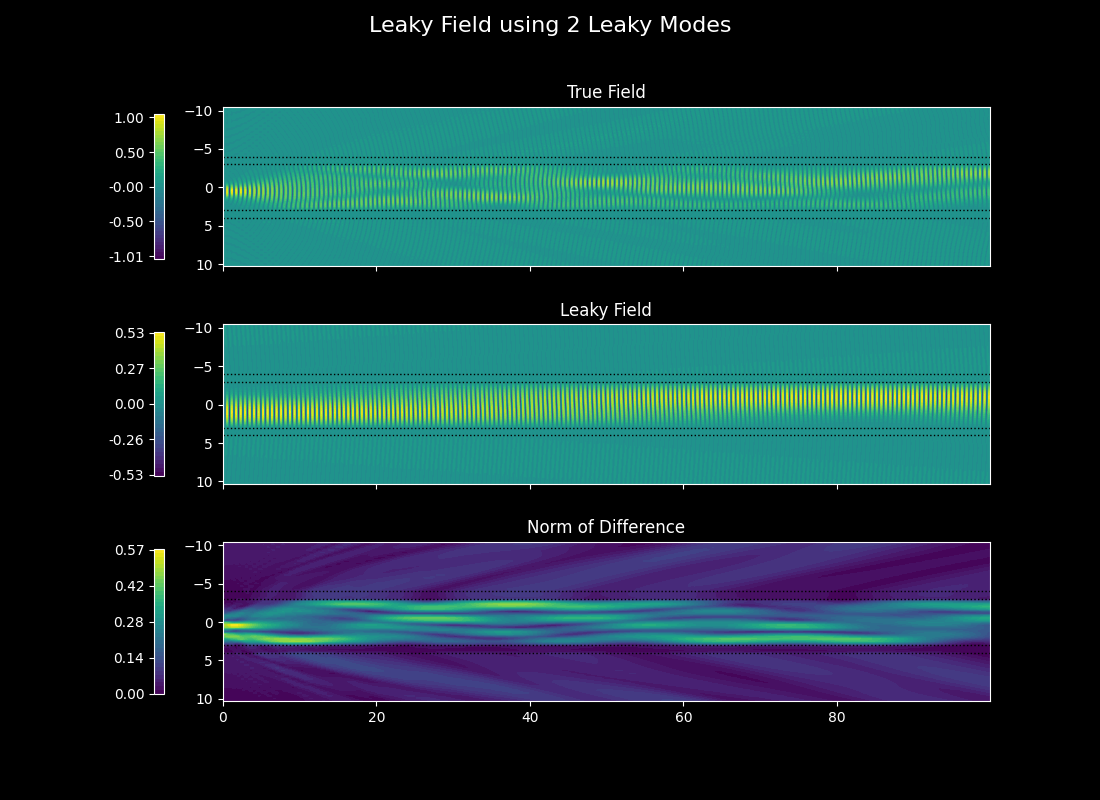

In [147]:
Leaky_2 = P.get_leaky_field(indices=np.arange(2))

plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(11,8))
fig.suptitle('Leaky Field using %i Leaky Modes'%2, fontsize=16)
zmin = 0
zmax = 100
zref = int((zmax-zmin)*20)
zs = np.linspace(zmin, zmax, zref)

A.add_2d_plot(P.Full, ax=ax1, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax1.set_title('True Field');

A.add_2d_plot(Leaky_2, ax=ax2, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax2.set_title('Leaky Field');

A.add_2d_plot(np.abs(P.Radiation - Leaky_2), ax=ax3, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax3.set_title('Norm of Difference');

Most detail is still missing from the leaky field in this case, so we increase the number of leaky modes we are using.

### 4 Modes

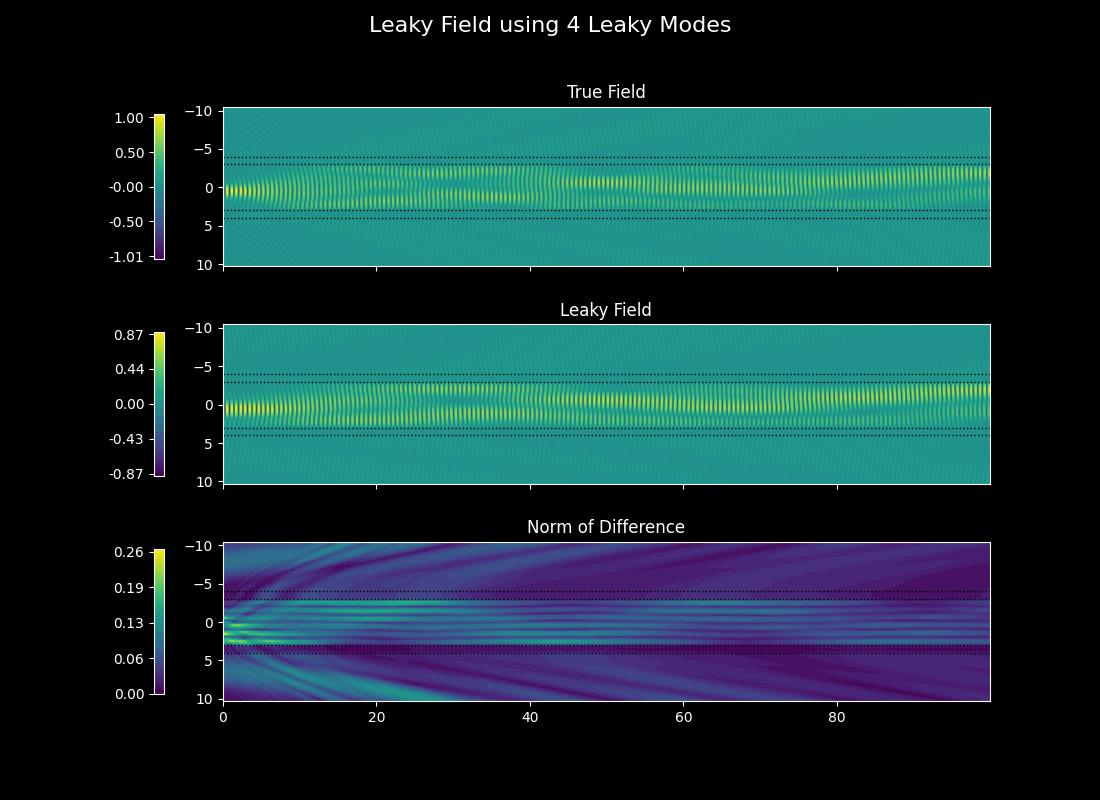

In [148]:
Leaky_4 = P.get_leaky_field(indices=np.arange(4))

plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(11,8))
fig.suptitle('Leaky Field using %i Leaky Modes'%4, fontsize=16)
zmin = 0
zmax = 100
zref = int((zmax-zmin)*20)
zs = np.linspace(zmin, zmax, zref)

A.add_2d_plot(P.Full, ax=ax1, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax1.set_title('True Field');

A.add_2d_plot(Leaky_4, ax=ax2, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax2.set_title('Leaky Field');

A.add_2d_plot(np.abs(P.Radiation - Leaky_4), ax=ax3, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax3.set_title('Norm of Difference');

We still are missing a lot, there appears to be 6 bands in the core region we are missing.  This is not surprising as the leaky modes have increasing numbers of oscillations in the core region as their real parts increase.  We now move to 6 modes

### 6 Modes

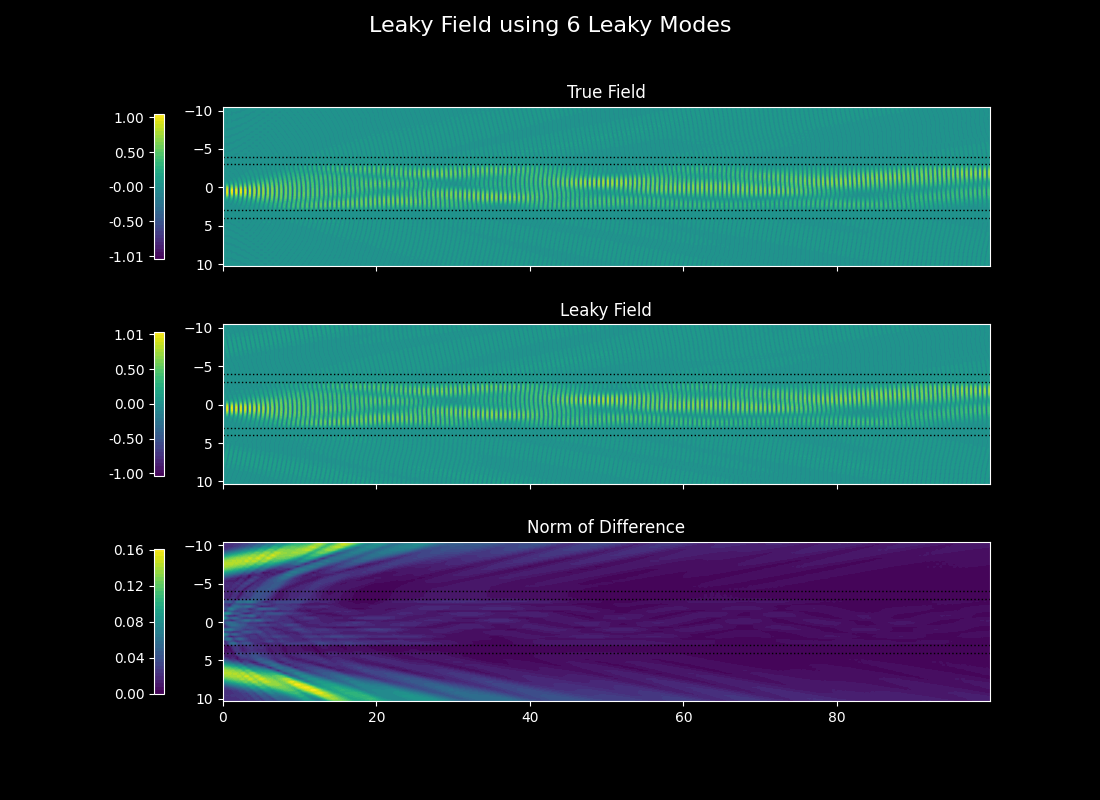

In [149]:
Leaky_6 = P.get_leaky_field(indices=np.arange(6))

plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(11,8))
fig.suptitle('Leaky Field using %i Leaky Modes'%6, fontsize=16)
zmin = 0
zmax = 100
zref = int((zmax-zmin)*20)
zs = np.linspace(zmin, zmax, zref)

A.add_2d_plot(P.Full, ax=ax1, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax1.set_title('True Field');

A.add_2d_plot(Leaky_6, ax=ax2, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax2.set_title('Leaky Field');

A.add_2d_plot(np.abs(P.Radiation - Leaky_6), ax=ax3, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax3.set_title('Norm of Difference');

By now we are largely capturing the behavior in the core.  The are still missing bands, but they are ephemeral, decaying to small values by the time the longitudinal coordinate is approximately 40.  Finally, we consider 8 modes:

### 8 Modes

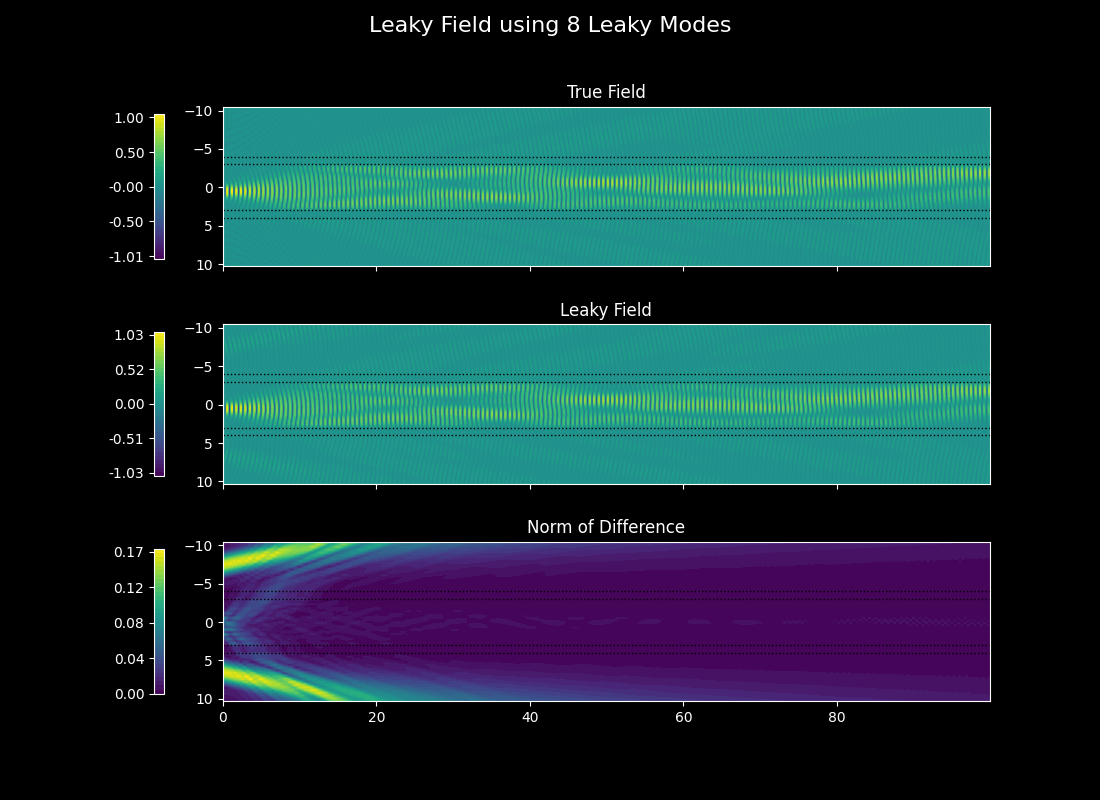

In [150]:
Leaky_8 = P.get_leaky_field(indices=np.arange(8))

plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(11,8))
fig.suptitle('Leaky Field using %i Leaky Modes'%8, fontsize=16)
zmin = 0
zmax = 100
zref = int((zmax-zmin)*20)
zs = np.linspace(zmin, zmax, zref)

A.add_2d_plot(P.Full, ax=ax1, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax1.set_title('True Field');

A.add_2d_plot(Leaky_8, ax=ax2, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax2.set_title('Leaky Field');

A.add_2d_plot(np.abs(P.Radiation - Leaky_8), ax=ax3, zs=zs, layout='horizontal', colorbar=True,
              colorbar_frac=.05, shrink=.8,);
ax3.set_title('Norm of Difference');

At this point, we have captured the asymptotic behavior of the fields well (in the transverse region under consideration).  This shows that it is possible to use a fairly small number of leaky modes to express a complicated induced field.   We note that this complicated behavior, which appears to persist in the above figures, in fact is transient spatially, as we see in the next section. 

## Long term propagation

It is often the case that just one or two leaky modes are used to represent the long term behavior of the fields.  Here we asses to what degree that is permissible in this case.

### Decay rates

We found the leaky mode propagation constants using the transverse wavenumber $Z$ associated with the outer region of the guide.  To find the loss in the longitudinal direction we must calculate the longitudinal propagation constant $\beta$ using 

$$\beta^2 = k_0^2 n^2 - Z^2.$$

We can use a built in method for this:

In [187]:
betas = A.Beta_from_Zi(np.array(A.leaky_prop_constants)) / A.scale


The longitudinal propagation of a mode is given by the term  $e^{i \beta z},$
so the imaginary component of $\beta$ determines the decay rate.  

In [188]:
betas.imag

array([3.59602576e+00, 2.89080987e+01, 9.88695748e+01, 2.41151255e+02,
       4.96097366e+02, 9.31843635e+02, 1.67197414e+03, 2.94636198e+03,
       5.18346532e+03, 9.13042516e+03, 1.52142742e+04, 1.98288270e+04,
       1.89329692e+04, 1.54754975e+04, 1.32589109e+04, 1.24682298e+04,
       1.28738783e+04, 1.45855414e+04, 1.81709144e+04, 2.50548496e+04,
       3.88400651e+04, 7.01992396e+04, 1.50066657e+05])

The above values are in decibels per meter.  Examining the relative orders, it is clear that only the fundamental mode will persist after even a quarter of a meter.  The following cells indicate this visually:

In [189]:
def longitudinal_prop(beta):
    def f(x, z):
        return f0(x) * np.exp(1j * beta * z)
    return f

In [190]:
E1 = longitudinal_prop(betas[0])
E2 = longitudinal_prop(betas[1])
E3 = longitudinal_prop(betas[2])

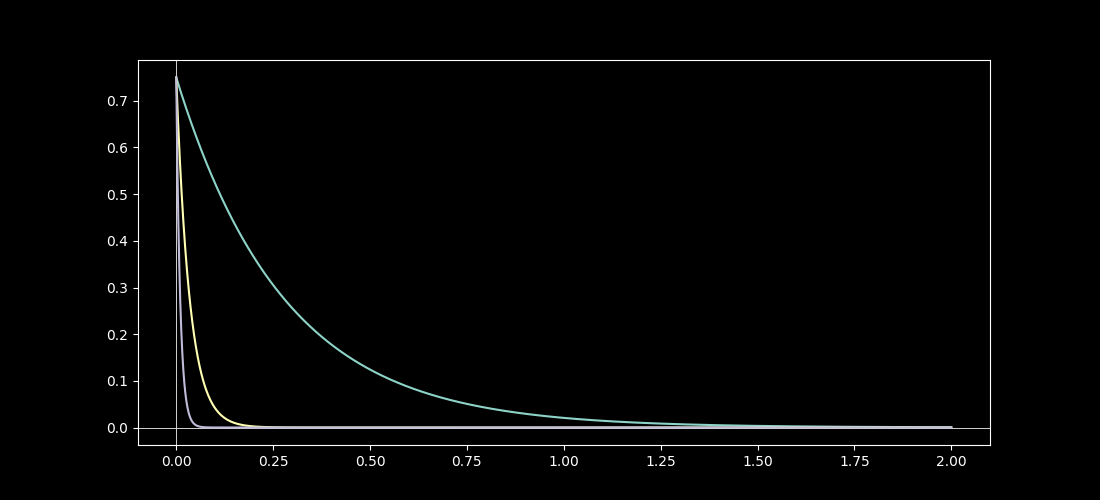

In [217]:
A.plot_field_1d(E1, zs=np.linspace(0,2, 10000), part='norm')
A.add_1d_plot(E2, zs=np.linspace(0,2, 10000), part='norm')
A.add_1d_plot(E3, zs=np.linspace(0,2, 10000), part='norm')

We now see where to look along the direction of propagation to find the "steady state" spatial behavior, namely between .25 and .5 dimensional units:

In [234]:
Zmin= .25 / A.scale
Zmax = Zmin + 150
Zmin, Zmax

(24999.999999999996, 25149.999999999996)

Plotting our original leaky field (found with 23 modes), we expect to only be able to discern the fundamental mode:

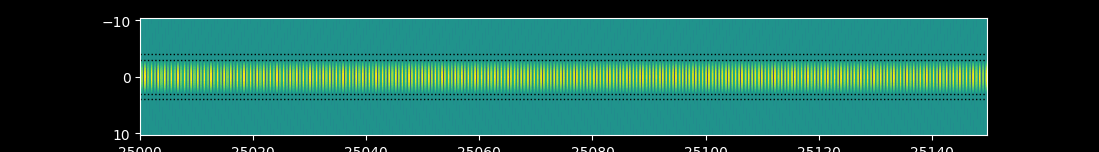

In [235]:
A.plot_field_2d(Leaky, zmin=Zmin, zmax=Zmax, zref=int((Zmax-Zmin)*6),
                colorbar_nticks=5, maxdim=11, layout='horizontal',
                colorbar=False,
               );

To see just the first two modes together, we should look near dimensional coordinate $z=.025$.

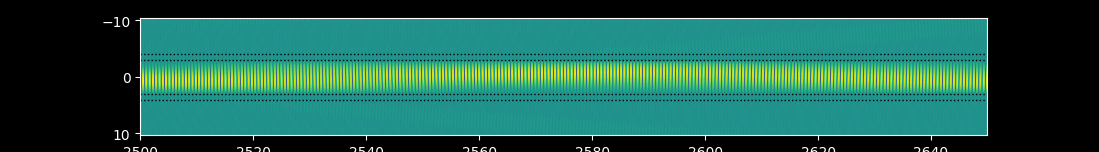

In [239]:
Zmin= .025 / A.scale
Zmax = Zmin + 150
Zmin, Zmax
A.plot_field_2d(Leaky, zmin=Zmin, zmax=Zmax, zref=int((Zmax-Zmin)*20),
                colorbar_nticks=5, maxdim=11, layout='horizontal',
                colorbar=False,
               );

Or to see three modes together, we look even nearer to the input end, .01 meters:

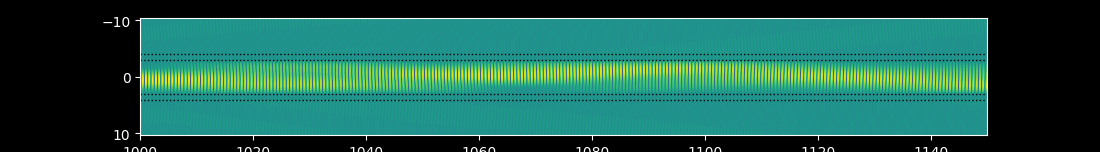

In [241]:
Zmin= .01 / A.scale
Zmax = Zmin + 150
Zmin, Zmax
A.plot_field_2d(Leaky, zmin=Zmin, zmax=Zmax, zref=int((Zmax-Zmin)*20),
                colorbar_nticks=5, maxdim=11, layout='horizontal',
                colorbar=False,
               );

# Conclusion

This hollow core guide was chosen for its ability to demonstrate both the leaky mode representation of input fields and its exhibition or resonance phenomena, the latter of which we will explore in later notebooks.

Regarding the leaky mode field, we have seen that it represents the true fields in this device well after short distances in the longitudinal direction.  What we have not shown is that it represents these fields well after very long distances. The reason for this is the same reason we use leaky modes: it is prohibitively expensive to calculate the semi-analytic fields in the guide at great distances in the direction of propagation.  Instead we rely on the theory of leaky modes, which tells us, essentially, that these modes approximate the true fields asymptotically in that direction, while requiring almost no computational power (once the modes have been found) to do so.

Regarding the word "essentially" in the last paragraph, it is there to recall the fact that the leaky mode field is not a complete representation of the true field in the device: another portion, arising from integrating along a particular contour in the complex plane, remains.  This piece of the field becomes very important for representing the true fields in the case of resonance phenomena.  It can also arise in unexpected situations, as we see in the next example.